# 03 不同局面下的得分期望（RE24 雏形）

## 这一步做了什么
把逐球数据聚合到打席层面，按"出局数 × 跑垒员状态"划分 24 个局面，
计算每个局面下从该打席起到本局结束的平均得分，并用柱状图展示。

## 数据从哪来
- 输入：`data/raw/*_statcast.csv`（Day 1 产出，本步额外需要 `bat_score` / `post_bat_score`）
- 状态量：`outs_when_up`、`on_1b` / `on_2b` / `on_3b`

## 结果是什么
- 图：`figures/2025-06-14_run_expectancy.png`（3 个子图，分别对应 0/1/2 出局）
- 表：`data/processed/2025-06-14_re24_table.csv`（24 个状态的均值、样本量、标准误）

## 与官方 RE24 表的区别
官方 RE24 表基于数十年、数十万打席估计；本表基于单日（或数周）样本，
数值会有明显偏差，但"出局越多期望越低、跑者越多期望越高"的规律应当成立。


In [19]:
# ===== 环境与路径 =====
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pybaseball as pb
from pybaseball import cache

cache.enable()   # 补抓数据时走本地缓存，不重复联网

def find_project_root(marker="requirements.txt") -> Path:
    """向上查找项目根目录"""
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / marker).exists():
            return cand
    return p

ROOT = find_project_root()
DATE = "2025-06-14"
RAW_PATH = ROOT / "data" / "raw" / f"{DATE}_statcast.csv"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 中文字体设置（Windows 用微软雅黑；Linux/Mac 会自动跳过不存在的字体）
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("项目根目录:", ROOT)


项目根目录: C:\Users\GOOD\PycharmProjects\Baseball-Analytics


In [20]:
# ===== 检查 Day 1 的 CSV 是否含有得分列，缺了就用缓存补抓 =====
SCORE_COLS = ["bat_score", "post_bat_score", "post_home_score", "post_away_score"]

if not RAW_PATH.exists():
    raise FileNotFoundError(f"找不到 {RAW_PATH}，请先跑完 Day 1")

existing = pd.read_csv(RAW_PATH, nrows=0).columns.tolist()
missing = [c for c in SCORE_COLS if c not in existing]

if missing:
    print("缺少列:", missing, "→ 开始补抓（命中缓存的话只需几秒）")
    raw = pb.statcast(start_dt=DATE, end_dt=DATE, verbose=False)

    # 保留原有列 + 新增得分列
    keep = [c for c in (existing + SCORE_COLS) if c in raw.columns]
    raw = raw[keep].copy()
    raw["game_date"] = pd.to_datetime(raw["game_date"]).dt.strftime("%Y-%m-%d")
    raw.to_csv(RAW_PATH, index=False, encoding="utf-8-sig")

    print("已覆盖保存:", RAW_PATH, raw.shape)
else:
    print("得分列齐全，无需补抓")


得分列齐全，无需补抓


In [21]:
# ===== 读入所有逐球文件，合并后去重 =====
files = sorted((ROOT / "data" / "raw").glob("*_statcast*.csv"))
print("读入文件:")
for f in files:
    print("  -", f.name)

df = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
df["game_date"] = pd.to_datetime(df["game_date"])

# 按"比赛 + 打席 + 球序"去重，防止单日文件与多月文件重复计入
before = len(df)
df = df.drop_duplicates(subset=["game_pk", "at_bat_number", "pitch_number"]).reset_index(drop=True)
print(f"\n原始 {before} 行 → 去重后 {len(df)} 行")
print("覆盖比赛场数:", df["game_pk"].nunique())


读入文件:
  - 2025-06-14_statcast.csv
  - 2025-06_statcast_month.csv

原始 120251 行 → 去重后 115816 行
覆盖比赛场数: 397


## 计算思路（三步）

**第一步：求每个半局最终得分**
按 (game_pk, inning, inning_topbot) 分组，取 `post_bat_score` 的最大值。
进攻方得分是累计值，所以半局结束时它一定取到最大值。

**第二步：求每个打席"之后还能得几分"**
`runs_to_end = 半局最终得分 − 该打席第一球的 bat_score`。
这个差值包含本打席打出的得分，符合 RE 的定义。

**第三步：打上状态标签**
`outs = outs_when_up`，`base = has_on_1b + has_on_2b + has_on_3b`（拼成三位 0/1 字符串），
按 (outs, base) 分组求均值。


In [22]:
# ===== 第一步 + 第二步：把逐球数据整理成"每个打席一行" =====
for b in ["on_1b", "on_2b", "on_3b"]:
    if f"has_{b}" not in df.columns:
        df[f"has_{b}"] = df[b].notna().astype(int)

df = df.sort_values(["game_pk", "inning", "inning_topbot", "at_bat_number", "pitch_number"])

KEY = ["game_pk", "inning", "inning_topbot"]

# 得分列补缺：半局开始前比分记 0；个别缺失按半局内前值填充
df["bat_score"] = df["bat_score"].fillna(0)
df["post_bat_score"] = df.groupby(KEY)["post_bat_score"].ffill()

# 半局最终得分（累计得分的最大值）
df["half_final"] = df.groupby(KEY)["post_bat_score"].transform("max")

# 取每个打席的第一球，读取"打席开始前"的状态
pa = df.drop_duplicates(subset=["game_pk", "at_bat_number"], keep="first").copy()

# 该打席起到本局结束的得分
pa["runs_to_end"] = pa["half_final"] - pa["bat_score"]

# 合理性检查
n_neg = (pa["runs_to_end"] < 0).sum()
print(f"打席总数: {len(pa)}")
print(f"runs_to_end 为负的条数: {n_neg}（应为 0，否则说明得分列读取有问题）")

pa = pa[pa["runs_to_end"].notna()].copy()
print(f"得分期望取值范围: {pa['runs_to_end'].min():.0f} ~ {pa['runs_to_end'].max():.0f} 分")


打席总数: 30045
runs_to_end 为负的条数: 0（应为 0，否则说明得分列读取有问题）
得分期望取值范围: 0 ~ 8 分


In [23]:
# ===== 第三步：状态标签 + 分组统计 =====
ORDER = ["000", "100", "010", "001", "110", "101", "011", "111"]
LABELS = {
    "000": "空垒",   "100": "一垒",   "010": "二垒",   "001": "三垒",
    "110": "一二垒", "101": "一三垒", "011": "二三垒", "111": "满垒",
}

pa["base"] = (pa["has_on_1b"].astype(int).astype(str)
              + pa["has_on_2b"].astype(int).astype(str)
              + pa["has_on_3b"].astype(int).astype(str))
pa["outs"] = pa["outs_when_up"].astype(int)

re_table = (pa.groupby(["outs", "base"])["runs_to_end"]
              .agg(n="size", mean="mean", sd="std")
              .reset_index())
re_table["se"] = re_table["sd"] / np.sqrt(re_table["n"])

# 补齐 24 个状态（某些状态在样本中可能一次都没出现）
grid = pd.MultiIndex.from_product([[0, 1, 2], ORDER], names=["outs", "base"]).to_frame(index=False)
re_full = grid.merge(re_table, on=["outs", "base"], how="left")
re_full["label"] = re_full["base"].map(LABELS)

# 打印可视化结果
pivot = re_full.pivot(index="base", columns="outs", values="mean").reindex(ORDER)
pivot.index = [LABELS[b] for b in ORDER]
pivot.columns = [f"{c}出局" for c in pivot.columns]
print("得分期望表（行=跑垒员状态，列=出局数）：")
print(pivot.round(3).to_string())

# 样本量偏少的状态单独列出来
weak = re_full[(re_full["n"].notna()) & (re_full["n"] < 20)]
if len(weak):
    print(f"\n样本量不足 20 的状态有 {len(weak)} 个：")
    print(weak[["outs", "label", "n", "mean"]].to_string(index=False))


得分期望表（行=跑垒员状态，列=出局数）：
       0出局    1出局    2出局
空垒   0.500  0.276  0.103
一垒   0.871  0.541  0.242
二垒   1.014  0.594  0.303
三垒   1.429  0.852  0.366
一二垒  1.516  0.936  0.473
一三垒  1.814  1.220  0.489
二三垒  1.953  1.539  0.673
满垒   2.130  1.681  0.738


In [24]:
# ===== 逻辑自检：
# 1) 同一垒位状态下，出局数增多，期望得分应下降
# 2) 同一出局数下，跑者增多，期望得分应上升
piv = re_full.pivot(index="base", columns="outs", values="mean").reindex(ORDER)

viol_out = (piv.diff(axis=1) > 0).sum().sum()          # 出局多反而得分升高的次数
viol_nan = piv.isna().sum().sum()

print(f"出局数与期望得分方向相反的格子: {viol_out} 个（理想值 0）")
print(f"缺失估计的状态数: {viol_nan} 个")

# 与公开 RE 表的量级对照（近几个赛季大联盟的近似值）
reference = {("000", 0): 0.48, ("111", 0): 2.20, ("000", 2): 0.09, ("111", 2): 0.65}
print("\n量级对照（本表 vs 参考值）：")
for (b, o), ref in reference.items():
    val = piv.loc[b, o]
    print(f"  {LABELS[b]} {o}出局: 本表 {val:.2f}  vs  参考 {ref:.2f}")


出局数与期望得分方向相反的格子: 0 个（理想值 0）
缺失估计的状态数: 0 个

量级对照（本表 vs 参考值）：
  空垒 0出局: 本表 0.50  vs  参考 0.48
  满垒 0出局: 本表 2.13  vs  参考 2.20
  空垒 2出局: 本表 0.10  vs  参考 0.09
  满垒 2出局: 本表 0.74  vs  参考 0.65


## 图形说明

- 三个子图分别对应 0、1、2 出局
- 每根柱子的一种颜色，横轴是 8 种跑垒员状态
- 误差线是 95% 置信区间（均值 ± 1.96 × 标准误）
- 柱子上方标注 `n=`，即该状态在样本中出现的打席数

读图要点：从左到右跑垒员逐渐增多，柱子应当逐步升高；从左图到右图出局数增加，柱子应当整体变矮。


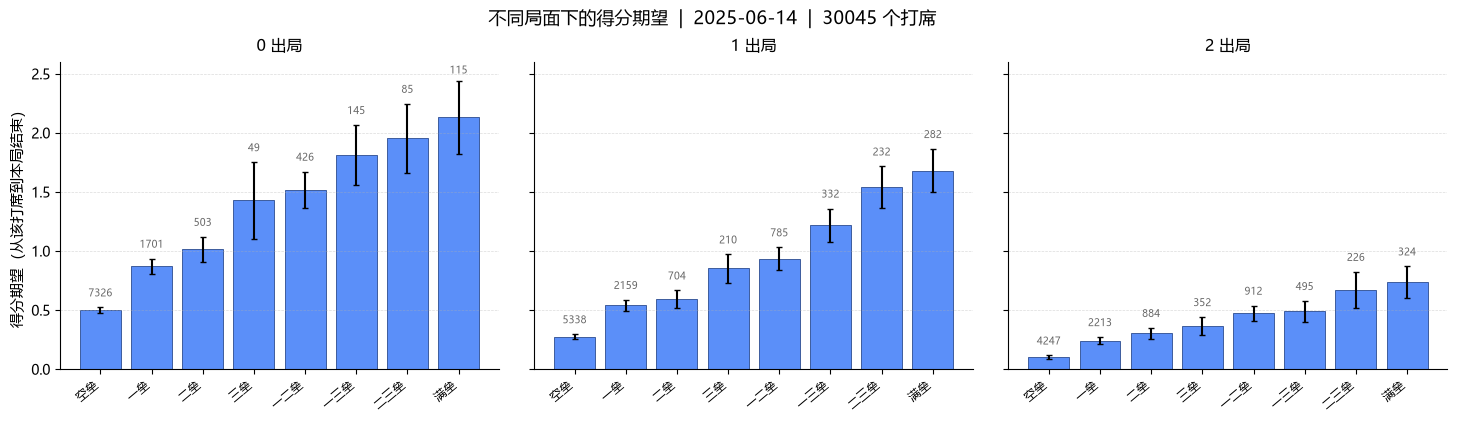

图片已保存: C:\Users\GOOD\PycharmProjects\Baseball-Analytics\figures\2025-06-14_run_expectancy.png
画布尺寸(英寸): [15.   4.8]


In [25]:
# ===== 画图: 3 个子图 × 8 种跑垒员状态 =====
Y_MAX = 2.6          # 纵轴上限，固定住，避免各子图比例不一致
N_MIN_TRUST = 10     # 样本量低于此值视为不可信，不画误差线并标灰

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

# 关键：手动控制四周边距，不用 tight_layout
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.065, right=0.99, top=0.84, bottom=0.20, wspace=0.08)

for ax, outs in zip(axes, [0, 1, 2]):
    ax.set_facecolor("white")

    sub = re_full[re_full["outs"] == outs].set_index("base").reindex(ORDER)
    x    = np.arange(len(ORDER))
    vals = sub["mean"].to_numpy(dtype=float)
    ns   = sub["n"].to_numpy(dtype=float)
    ses  = sub["se"].to_numpy(dtype=float)

    # 样本量不足时不画误差线；同时给误差线设上限，防止它顶出画面
    err = np.where((ns >= N_MIN_TRUST) & np.isfinite(ses), 1.96 * ses, 0.0)
    err = np.minimum(err, 0.5)

    # 不可信的状态用浅灰，可靠用蓝色
    colors = ["#5B8FF9" if (pd.notna(n) and n >= N_MIN_TRUST) else "#C9C9C9" for n in ns]

    ax.bar(x, np.nan_to_num(vals), yerr=err, capsize=2.5,
           color=colors, edgecolor="#2B4B8F", linewidth=0.6)

    # 标注样本量：位置限制在轴内，clip_on=True 防止溢出画布
    for i, (v, n) in enumerate(zip(vals, ns)):
        if pd.isna(v):
            continue
        y_text = min(np.nan_to_num(v) + err[i] + 0.07, Y_MAX - 0.12)
        ax.text(i, y_text, f"{int(n)}", ha="center", va="bottom",
                fontsize=7.5, color="#666666", clip_on=True)

    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[b] for b in ORDER], rotation=40,
                       ha="right", fontsize=8.5)
    ax.set_title(f"{outs} 出局", fontsize=11.5, pad=8)
    ax.set_ylim(0, Y_MAX)
    ax.set_yticks(np.arange(0, Y_MAX + 0.1, 0.5))
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.45)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("得分期望（从该打席到本局结束）", fontsize=10.5)

fig.suptitle(f"不同局面下的得分期望  |  {DATE}  |  {len(pa)} 个打席",
             fontsize=13, y=0.95)

out_fig = FIG_DIR / f"{DATE}_run_expectancy.png"
fig.savefig(out_fig, dpi=150, facecolor="white")   # 不加 bbox_inches="tight"
plt.show()
print("图片已保存:", out_fig)
print("画布尺寸(英寸):", fig.get_size_inches())


In [26]:
# ===== 保存 24 状态表 =====
out_tbl = PROC_DIR / f"{DATE}_re24_table.csv"
re_full[["outs", "base", "label", "n", "mean", "sd", "se"]].to_csv(
    out_tbl, index=False, encoding="utf-8-sig")
print("表格已保存:", out_tbl)

# ===== 文字结论 =====
best = re_full.dropna(subset=["mean"]).sort_values("mean", ascending=False).iloc[0]
worst = re_full.dropna(subset=["mean"]).sort_values("mean").iloc[0]
print("\n=== 当日结论 ===")
print(f"共 {len(pa)} 个打席，覆盖 {df['game_pk'].nunique()} 场比赛。")
print(f"期望得分最高的局面：{best['label']}、{int(best['outs'])} 出局，"
      f"{best['mean']:.2f} 分（n={int(best['n'])}）")
print(f"期望得分最低的局面：{worst['label']}、{int(worst['outs'])} 出局，"
      f"{worst['mean']:.2f} 分（n={int(worst['n'])}）")


表格已保存: C:\Users\GOOD\PycharmProjects\Baseball-Analytics\data\processed\2025-06-14_re24_table.csv

=== 当日结论 ===
共 30045 个打席，覆盖 397 场比赛。
期望得分最高的局面：满垒、0 出局，2.13 分（n=115）
期望得分最低的局面：空垒、2 出局，0.10 分（n=4247）


In [27]:
# ===== 可选：抓一个月的数据，让 24 个状态的样本量更可靠 =====
def fetch_period(start_dt: str, end_dt: str, out_name: str) -> Path:
    """抓取一个日期区间的逐球数据，列与 Day 1 保持一致（含得分列）。"""
    keep = ["game_date", "pitcher", "batter", "release_speed", "events",
            "launch_speed", "launch_angle", "game_pk", "game_type",
            "home_team", "away_team", "inning", "inning_topbot", "outs_when_up",
            "on_1b", "on_2b", "on_3b", "at_bat_number", "pitch_number",
            "description", "type", "bb_type", "stand", "p_throws",
            "bat_score", "post_bat_score", "post_home_score", "post_away_score"]

    d = pb.statcast(start_dt=start_dt, end_dt=end_dt, verbose=True)
    d = d[[c for c in keep if c in d.columns]].copy()
    d["game_date"] = pd.to_datetime(d["game_date"]).dt.strftime("%Y-%m-%d")
    path = ROOT / "data" / "raw" / out_name
    d.to_csv(path, index=False, encoding="utf-8-sig")
    print("已保存:", path, d.shape)
    return path

# 想扩大样本时取消下面这行的注释，然后重新运行单元格 4 及之后的所有单元格
fetch_period("2025-06-01", "2025-06-30", "2025-06_statcast_month.csv")


This is a large query, it may take a moment to complete


100%|██████████| 30/30 [00:00<00:00, 30.30it/s]


已保存: C:\Users\GOOD\PycharmProjects\Baseball-Analytics\data\raw\2025-06_statcast_month.csv (115816, 28)


WindowsPath('C:/Users/GOOD/PycharmProjects/Baseball-Analytics/data/raw/2025-06_statcast_month.csv')